## Taxi Demand and the Role of Taxi Stands (Flag 5)

### Dataset Overview
The main table contains 120 completed taxi trips sampled from the UCI Porto Taxi data for one observed day. It retains taxi identity, request source, origin-stand identifier, timestamps and trip boundaries. The reference table contains the original GPS points for these trips.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze how taxi demand is distributed over one day and examine the role of taxi stands in that demand.

Role: Urban taxi demand analyst


Category: Overall Characterization

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trips.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does taxi demand change across the day, and which request source dominates the busiest period?

#### Analysis action

Compare the hourly demand profile with the contribution of each request source.

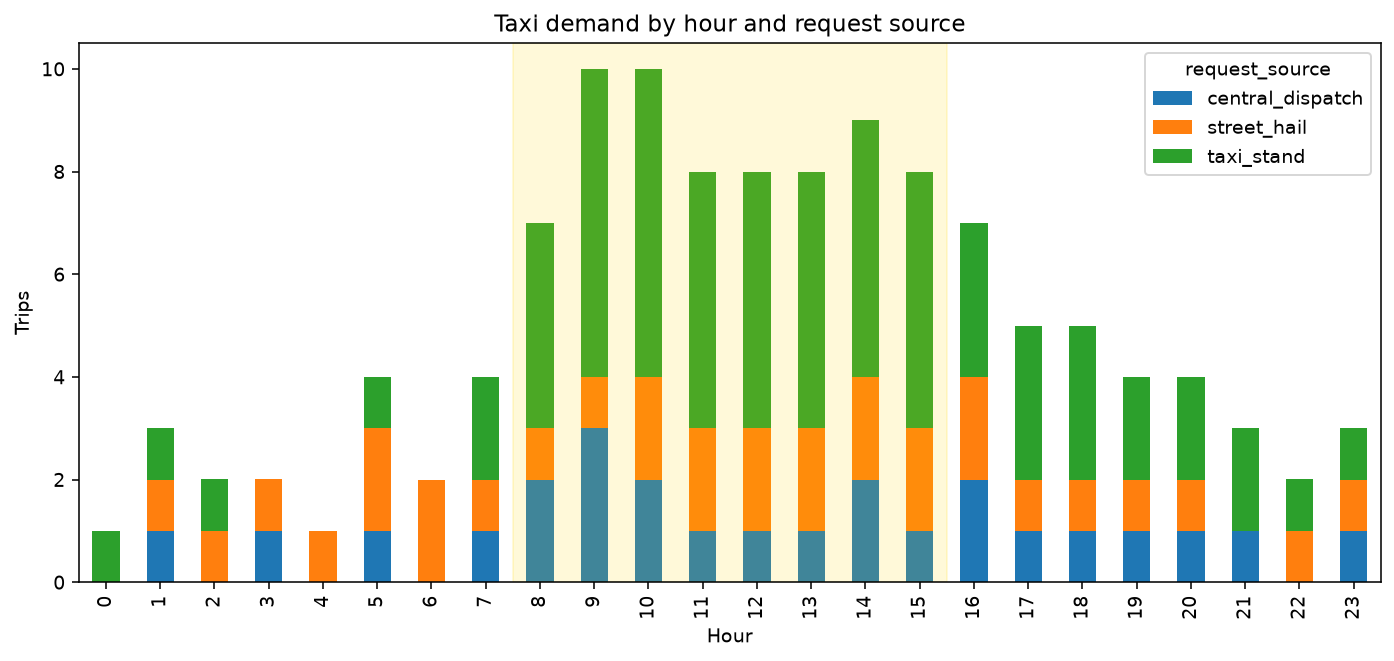

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d = pd.read_csv(dataset_path)
d['timestamp'] = pd.to_datetime(d['timestamp'])
d['hour'] = d['timestamp'].dt.hour
counts = d.pivot_table(index='hour', columns='request_source', values='trip_id', aggfunc='count', fill_value=0)
counts.reindex(range(24), fill_value=0).plot(kind='bar', stacked=True, figsize=(12,5))
plt.axvspan(8-0.5, 16-0.5, color='gold', alpha=.15)
plt.title('Taxi demand by hour and request source'); plt.xlabel('Hour'); plt.ylabel('Trips'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q1_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "temporal",
  "insight": "08:00–16:00 is the busiest period in the selected day, and taxi-stand-originated requests are the dominant source during this period, accounting for slightly more than half of the requests.",
  "insight_value": {
    "peak_period": "08:00–16:00",
    "dominant_request_source": "taxi-stand-originated requests"
  },
  "plot": {
    "plot_type": "stacked_bar_chart",
    "title": "Taxi Demand by Hour and Request Source",
    "file": "notebook_plots/q1_1.png",
    "description": "Hourly demand is separated into central-dispatch, taxi-stand-originated and street-hail requests."
  },
  "question": "How does taxi demand change across the day, and which request source dominates the busiest period?",
  "actionable_insight": "Compare the hourly demand profile with the contribution of each request source.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd = pd.read_csv('trips.csv')\nd['timestamp'] = pd.to_datetime(d['timestamp'])\nd['hour'] = d['timestamp'].dt.hour\ncounts = d.pivot_table(index='hour', columns='request_source', values='trip_id', aggfunc='count', fill_value=0)\ncounts.reindex(range(24), fill_value=0).plot(kind='bar', stacked=True, figsize=(12,5))\nplt.axvspan(8-0.5, 16-0.5, color='gold', alpha=.15)\nplt.title('Taxi demand by hour and request source'); plt.xlabel('Hour'); plt.ylabel('Trips'); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "request_source",
    "trajectory_id"
  ]
}

### **Question 2**: Are central-dispatch requests handled by a separate fleet, or by taxis that also serve taxi stands?

#### Analysis action

Compare request-source counts at the taxi level; do not infer an unrecorded physical waiting state.

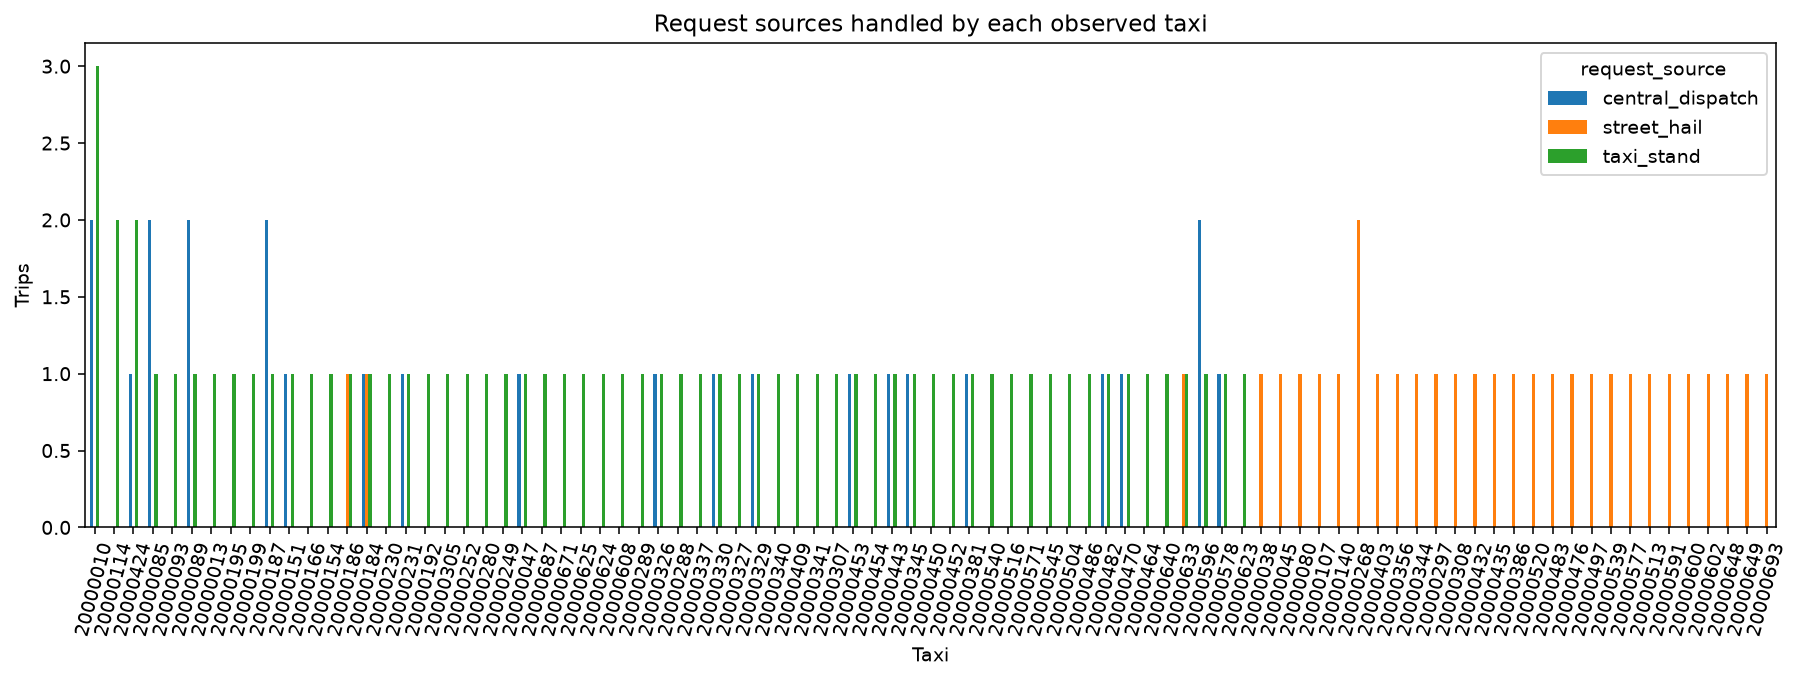

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d = pd.read_csv(dataset_path)
counts = d.pivot_table(index='taxi_id', columns='request_source', values='trip_id', aggfunc='count', fill_value=0)
counts.sort_values('taxi_stand', ascending=False).plot(kind='bar', stacked=False, figsize=(13,5))
plt.title('Request sources handled by each observed taxi'); plt.xlabel('Taxi'); plt.ylabel('Trips'); plt.xticks(rotation=75); plt.tight_layout(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q2_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight": "Central-dispatch requests are handled almost entirely by taxis that also appear in taxi-stand-originated service during the same observed day, indicating that stand-based service is associated with a shared fleet rather than a separate fleet.",
  "insight_value": {
    "unit_of_analysis": "taxi_id",
    "comparison": "central_dispatch and taxi_stand service overlap"
  },
  "plot": {
    "plot_type": "grouped_bar_chart",
    "title": "Request Sources by Taxi",
    "file": "notebook_plots/q2_1.png",
    "description": "The number of trips from each request source is shown for each observed taxi."
  },
  "question": "Are central-dispatch requests handled by a separate fleet, or by taxis that also serve taxi stands?",
  "actionable_insight": "Compare request-source counts at the taxi level; do not infer an unrecorded physical waiting state.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd = pd.read_csv('trips.csv')\ncounts = d.pivot_table(index='taxi_id', columns='request_source', values='trip_id', aggfunc='count', fill_value=0)\ncounts.sort_values('taxi_stand', ascending=False).plot(kind='bar', stacked=False, figsize=(13,5))\nplt.title('Request sources handled by each observed taxi'); plt.xlabel('Taxi'); plt.ylabel('Trips'); plt.xticks(rotation=75); plt.tight_layout(); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "taxi_id",
    "request_source",
    "trajectory_id"
  ]
}

### **Question 3**: How does taxi-stand-originated demand change after the daytime high-demand period, particularly during the night?

#### Analysis action

Compare absolute taxi-stand request counts by hour rather than only their proportions.

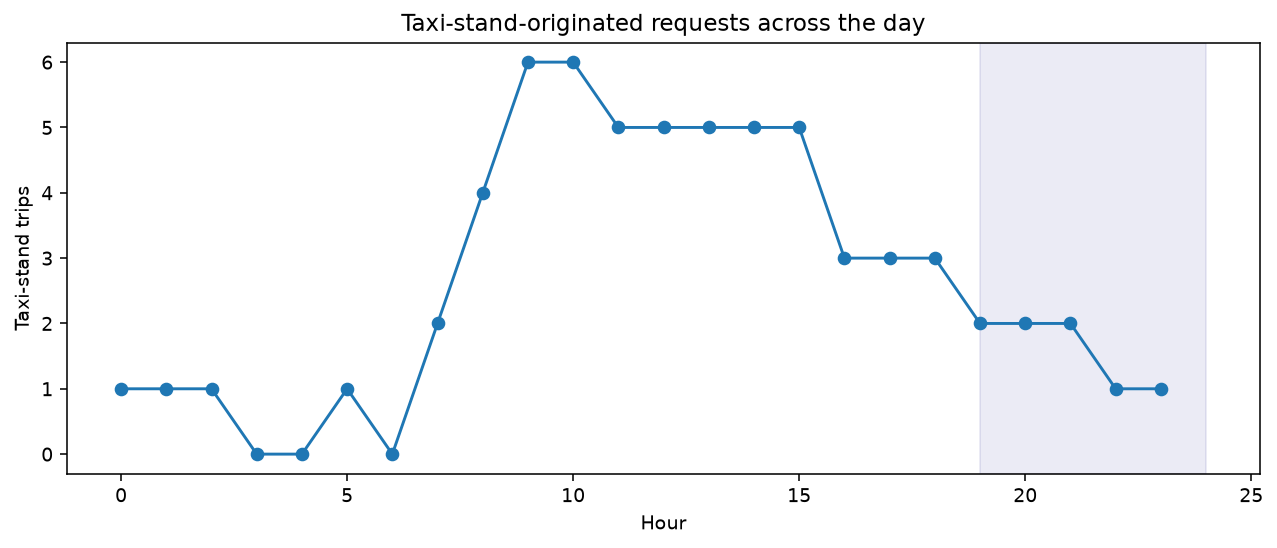

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d = pd.read_csv(dataset_path)
d['timestamp'] = pd.to_datetime(d['timestamp'])
d['hour'] = d['timestamp'].dt.hour
stand = d[d['request_source'] == 'taxi_stand'].groupby('hour').size().reindex(range(24), fill_value=0)
stand.plot(kind='line', marker='o', figsize=(11,4))
plt.axvspan(19, 24, color='navy', alpha=.08)
plt.title('Taxi-stand-originated requests across the day'); plt.xlabel('Hour'); plt.ylabel('Taxi-stand trips'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="notebook_plots/q3_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "temporal",
  "insight": "Outside the high-demand period, especially during the night, the absolute number of taxi-stand-originated requests is much lower than during daytime peak hours, although taxi stands remain active.",
  "insight_value": {
    "comparison": "taxi-stand request counts across daytime and nighttime hours"
  },
  "plot": {
    "plot_type": "line_chart",
    "title": "Taxi-Stand Requests Across the Day",
    "file": "notebook_plots/q3_1.png",
    "description": "The hourly volume of taxi-stand-originated requests is plotted across the full day."
  },
  "question": "How does taxi-stand-originated demand change after the daytime high-demand period, particularly during the night?",
  "actionable_insight": "Compare absolute taxi-stand request counts by hour rather than only their proportions.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd = pd.read_csv('trips.csv')\nd['timestamp'] = pd.to_datetime(d['timestamp'])\nd['hour'] = d['timestamp'].dt.hour\nstand = d[d['request_source'] == 'taxi_stand'].groupby('hour').size().reindex(range(24), fill_value=0)\nstand.plot(kind='line', marker='o', figsize=(11,4))\nplt.axvspan(19, 24, color='navy', alpha=.08)\nplt.title('Taxi-stand-originated requests across the day'); plt.xlabel('Hour'); plt.ylabel('Taxi-stand trips'); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "request_source",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 5)

On the selected Porto day, taxi demand is concentrated in the daytime, with 08:00–16:00 as the busiest period. Taxi-stand-originated requests are the dominant but not exclusive daytime source, and the taxis serving central dispatch also largely overlap with the taxi-stand service fleet. Taxi-stand demand falls substantially at night in absolute terms while remaining present.